# Estructuras — 01: NSR-10 worked example

A 5-storey reinforced-concrete moment-frame building:
1. seismic design spectrum and equivalent lateral forces (NSR-10 Título A),
2. beam flexure and shear design (Título C),
3. column P–M interaction diagram and check (Título C).

**Aa and Av are example values** — take the real ones for your municipality from NSR-10 Appendix A-4
or the local microzonation study. Units: mm, MPa, kN, kN·m (seismic: m, s, g).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from structools import concreto as rc, sismo

## 1. Design spectrum and equivalent lateral forces

Fa = 1.50, Fv = 2.00, T0 = 0.178 s, TC = 0.853 s, TL = 4.80 s
Ta = 0.570 s  ->  Sa = 0.562 g


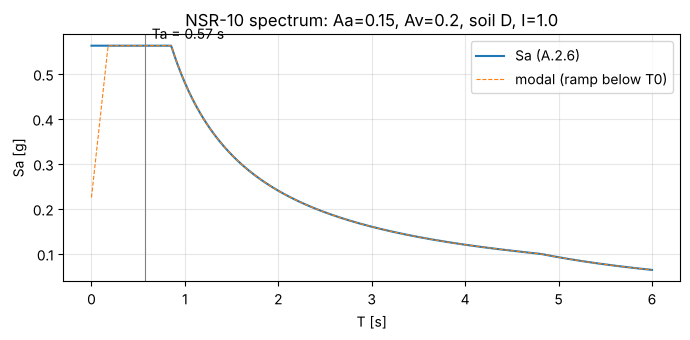

Vs = 11475 kN, k = 1.035
These are elastic forces Fs. For member design NSR-10 uses E = Fs / R, with R = φa φp φr R0 (A.3.3);
R0 = 7.0 for a DES concrete moment frame (Table A.3-3). Drifts are checked with the unreduced forces.


,level,h,W,Cvx,Fx,story_shear
0,1,3.2,4200.0,0.067,770.195,11475.000
1,2,6.4,4200.0,0.138,1578.167,10704.805
2,3,9.6,4200.0,0.209,2401.041,9126.638
3,4,12.8,4200.0,0.282,3233.743,6725.597
4,5,16.0,3600.0,0.304,3491.854,3491.854


In [2]:
Aa, Av, soil, group = 0.15, 0.20, "D", "I"
I = sismo.IMPORTANCE[group]
Fa, Fv = sismo.site_coefficients(soil, Aa, Av)
p = sismo.spectrum_periods(Aa, Av, Fa, Fv)
print(f"Fa = {Fa:.2f}, Fv = {Fv:.2f}, T0 = {p['T0']:.3f} s, TC = {p['TC']:.3f} s, TL = {p['TL']:.2f} s")

heights = np.arange(1, 6) * 3.2          # m
weights = [4200, 4200, 4200, 4200, 3600]  # kN per floor (dead + required live fraction)
Ta = sismo.approx_period(heights[-1], "concrete_moment_frame")
Sa_T = sismo.Sa(Ta, Aa, Av, soil, I)
print(f"Ta = {Ta:.3f} s  ->  Sa = {Sa_T:.3f} g")

T = np.linspace(0, 6, 600)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(T, sismo.Sa(T, Aa, Av, soil, I), label="Sa (A.2.6)")
ax.plot(T, sismo.Sa(T, Aa, Av, soil, I, short_period_ramp=True), "--", lw=0.8, label="modal (ramp below T0)")
ax.axvline(Ta, color="grey", lw=0.8); ax.annotate(f"Ta = {Ta:.2f} s", (Ta, Sa_T), xytext=(5, 5), textcoords="offset points")
ax.set_xlabel("T [s]"); ax.set_ylabel("Sa [g]"); ax.set_title(f"NSR-10 spectrum: Aa={Aa}, Av={Av}, soil {soil}, I={I}")
ax.grid(alpha=.3); ax.legend(); fig.tight_layout(); plt.show()

forces = sismo.elf(weights, heights, Sa_T, Ta)
print(f"Vs = {forces.attrs['Vs']:.0f} kN, k = {forces.attrs['k']:.3f}")
print("These are elastic forces Fs. For member design NSR-10 uses E = Fs / R, with R = φa φp φr R0 (A.3.3);")
print("R0 = 7.0 for a DES concrete moment frame (Table A.3-3). Drifts are checked with the unreduced forces.")
forces.round(3)

## 2. Beam: flexure and shear
300 × 500 mm beam, d = 440 mm, f'c = 28 MPa, fy = 420 MPa. Mu and Vu come from your frame analysis (e.g. `PyNiteFEA` or `openseespy`).

In [3]:
b, h, d, fc, fy = 300, 500, 440, 28, 420
Mu, Vu = 180.0, 160.0     # kN*m, kN

des = rc.design_flexure(Mu, b, d, fc, fy)
chk = des["check"]
print(f"As required = {des['As']:.0f} mm²  (ρ = {des['rho']:.4f}, As,min = {chk['As_min']:.0f} mm²)")
n8 = int(np.ceil(des["As"] / 510))
prov = rc.flexure_rect(b, d, n8 * 510, fc, fy)
print(f"Provide {n8} #8 = {n8*510} mm²: a = {prov['a']:.1f} mm, εt = {prov['eps_t']:.4f}, "
      f"φ = {prov['phi']:.2f}, φMn = {prov['phiMn']:.1f} kN·m  ->  {'OK' if prov['phiMn'] >= Mu else 'NO'}")

sh = rc.shear_design(Vu, b, d, fc, fy, Av=2 * 71)   # #3 stirrups, 2 legs
print(f"φVc = {sh['phiVc']:.1f} kN, Vs req = {sh['Vs_req']:.1f} kN -> s = {sh['s']:.0f} mm "
      f"(strength {sh['s_strength']:.0f}, max {sh['s_max']:.0f}, Av,min {sh['s_Avmin']:.0f})")
print("Note: DES/DMO confinement spacing (C.21) near supports usually governs - check it separately.")

As required = 1174 mm²  (ρ = 0.0089, As,min = 440 mm²)
Provide 3 #8 = 1530 mm²: a = 90.0 mm, εt = 0.0095, φ = 0.90, φMn = 228.4 kN·m  ->  OK
φVc = 89.1 kN, Vs req = 94.6 kN -> s = 220 mm (strength 277, max 220, Av,min 568)
Note: DES/DMO confinement spacing (C.21) near supports usually governs - check it separately.


## 3. Column: interaction diagram

Ast = 4080 mm² (ρg = 2.550%), P0 = 5424 kN, φPn,max = 2821 kN
Comb 1: Pu = 1500 kN, Mu = 120 kN·m -> ratio 0.70 OK
Comb 2: Pu = 900 kN, Mu = 210 kN·m -> ratio 0.89 OK
Comb 3: Pu = 400 kN, Mu = 260 kN·m -> ratio 0.97 OK


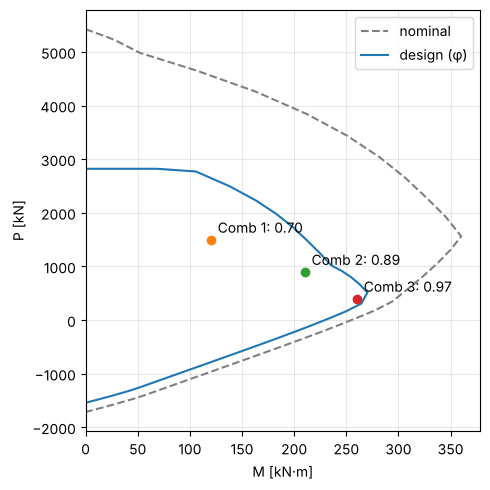

In [4]:
bc = hc = 400
bars = rc.rect_bars(bc, hc, cover=60, n_top=3, n_bot=3, n_side=1, bar_area=510)   # 8 #8
df = rc.interaction_diagram(bc, hc, bars, fc, fy)
Ast = sum(A for _, A in bars)
print(f"Ast = {Ast} mm² (ρg = {Ast/(bc*hc):.3%}), P0 = {df.attrs['P0']:.0f} kN, φPn,max = {0.65*df.attrs['Pn_max']:.0f} kN")

demands = {"Comb 1": (1500, 120), "Comb 2": (900, 210), "Comb 3": (400, 260)}
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(df["Mn"], df["Pn"], "--", color="grey", label="nominal")
ax.plot(df["phiMn"], df["phiPn"], label="design (φ)")
for name, (Pu, Mu_c) in demands.items():
    r = rc.column_check(Pu, Mu_c, df)
    ax.plot(Mu_c, Pu, "o")
    ax.annotate(f"{name}: {r['ratio']:.2f}", (Mu_c, Pu), xytext=(5, 5), textcoords="offset points")
    print(f"{name}: Pu = {Pu} kN, Mu = {Mu_c} kN·m -> ratio {r['ratio']:.2f} {'OK' if r['ok'] else 'FAILS'}")
ax.set_xlabel("M [kN·m]"); ax.set_ylabel("P [kN]"); ax.set_xlim(left=0); ax.grid(alpha=.3); ax.legend()
fig.tight_layout(); plt.show()